# OTT Viewer Engagement & Watch-Time Analysis

## Business Problem
The retention and product analytics team at an Indian OTT streaming platform wants to understand what drives subscribers to spend more time watching content each month. Subscribers with low monthly watch hours are far more likely to cancel their plans during the next billing cycle. By identifying which user behaviors, plans, and devices correlate with higher watch time, the team can improve its recommendation engine and run targeted re-engagement campaigns.

## Key Questions
1. What does `Monthly_Watch_Hours` look like overall?
2. Do `Weekly_App_Opens` and `Recommendation_Clicks` affect `Monthly_Watch_Hours`?
3. Does `Monthly_Watch_Hours` differ by `City`, `Subscription_Plan`, `Preferred_Genre`, and `Primary_Device`?
4. Which records need attention? (Flag subscribers with `Monthly_Watch_Hours < 25.0` as **"At Risk"**.)

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")

# Load raw dataset
df = pd.read_csv("../data/raw/ott_viewing_data.csv")

print("Shape:", df.shape)
display(df.head())

Shape: (255, 11)


,Viewer_ID,City,Subscription_Plan,Preferred_Genre,Primary_Device,Viewer_Age,Monthly_Fee_INR,Weekly_App_Opens,Recommendation_Clicks,Last_Active_Date,Monthly_Watch_Hours
0,V1057,Bengaluru,Mobile,Drama,Smartphone,20.0,149.0,21,3.0,2026-02-13,30.5
1,V1024,Pune,Premium,Action,Smartphone,45.0,749.0,23,22.0,2026-04-15,66.2
2,V1023,Delhi,Mobile,Thriller,Smartphone,56.0,249.0,16,20.0,2025-08-29,40.5
3,V1072,Delhi,Standard,Drama,Smart TV,46.0,499.0,30,25.0,2025-09-09,78.7
4,V1221,Delhi,Standard,Drama,Smartphone,43.0,599.0,28,11.0,2024-12-21,53.7


In [3]:
df.info()
display(df.describe())

print("\nMissing values per column:")
print(df.isna().sum())

print("\nExact duplicate rows:", df.duplicated().sum())

print("\nUnique values in category columns:")
for col in ["City", "Subscription_Plan", "Preferred_Genre", "Primary_Device"]:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))

<class 'pandas.DataFrame'>
RangeIndex: 255 entries, 0 to 254
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Viewer_ID              255 non-null    str    
 1   City                   255 non-null    str    
 2   Subscription_Plan      255 non-null    str    
 3   Preferred_Genre        251 non-null    str    
 4   Primary_Device         255 non-null    str    
 5   Viewer_Age             250 non-null    float64
 6   Monthly_Fee_INR        249 non-null    float64
 7   Weekly_App_Opens       255 non-null    int64  
 8   Recommendation_Clicks  250 non-null    float64
 9   Last_Active_Date       255 non-null    str    
 10  Monthly_Watch_Hours    255 non-null    float64
dtypes: float64(4), int64(1), str(6)
memory usage: 22.0 KB


,Viewer_Age,Monthly_Fee_INR,Weekly_App_Opens,Recommendation_Clicks,Monthly_Watch_Hours
count,250.000000,249.000000,255.000000,250.000000,255.000000
mean,39.704000,397.995984,16.352941,12.664000,48.415294
std,15.162586,211.630088,8.667124,7.558547,18.744483
min,-7.000000,149.000000,2.000000,0.000000,4.000000
25%,28.250000,149.000000,8.000000,6.000000,37.050000
50%,39.000000,499.000000,17.000000,13.000000,48.800000
75%,50.000000,599.000000,24.000000,19.000000,60.100000
max,172.000000,749.000000,30.000000,25.000000,94.700000



Missing values per column:
Viewer_ID                0
City                     0
Subscription_Plan        0
Preferred_Genre          4
Primary_Device           0
Viewer_Age               5
Monthly_Fee_INR          6
Weekly_App_Opens         0
Recommendation_Clicks    5
Last_Active_Date         0
Monthly_Watch_Hours      0
dtype: int64

Exact duplicate rows: 5

Unique values in category columns:

--- City ---
City
Mumbai         68
Delhi          61
Bengaluru      51
Hyderabad      37
Pune           31
mumbai          2
delhi           1
  Mumbai        1
 Bengaluru      1
 MUMBAI         1
DELHI           1
Name: count, dtype: int64

--- Subscription_Plan ---
Subscription_Plan
Mobile      116
Standard     90
Premium      49
Name: count, dtype: int64

--- Preferred_Genre ---
Preferred_Genre
Drama          78
Thriller       64
Comedy         45
Action         35
Documentary    29
NaN             4
Name: count, dtype: int64

--- Primary_Device ---
Primary_Device
Smartphone    126
Smart T

## Data Cleaning
From the inspection above, we found four data-quality issues:
1. **5 exact duplicate rows** — dropped so each subscriber is counted once.
2. **Inconsistent text in `City`** (extra spaces and mixed case like `"  Mumbai"`, `"DELHI"`, `" Bengaluru "`) — fixed with `.str.strip().str.title()`.
3. **2 impossible values in `Viewer_Age`** (`-7` and `172`, outside the valid range 18–60) — replaced with `NaN`.
4. **Missing values** in `Viewer_Age`, `Monthly_Fee_INR`, `Recommendation_Clicks`, and `Preferred_Genre` — filled numeric columns with their **median** (robust to outliers) and the categorical column with its **mode**.

In [4]:
# 1. Remove exact duplicates
df = df.drop_duplicates().reset_index(drop=True)

# 2. Standardize City text
df["City"] = df["City"].astype(str).str.strip().str.title()

# 3. Replace impossible Viewer_Age values with NaN
df.loc[(df["Viewer_Age"] < 18) | (df["Viewer_Age"] > 60), "Viewer_Age"] = np.nan

# 4. Fill missing numeric values with median
for col in ["Viewer_Age", "Monthly_Fee_INR", "Recommendation_Clicks"]:
    df[col] = df[col].fillna(round(df[col].median())).astype(int)

# 5. Fill missing Preferred_Genre with mode
df["Preferred_Genre"] = df["Preferred_Genre"].fillna(df["Preferred_Genre"].mode()[0])

# 6. Format types cleanly
df["Weekly_App_Opens"] = df["Weekly_App_Opens"].astype(int)
df["Last_Active_Date"] = pd.to_datetime(df["Last_Active_Date"]).dt.strftime("%Y-%m-%d")

# Verify clean data
print("Clean shape:", df.shape)
print("Missing values:\n", df.isna().sum())
print("Duplicates:", df.duplicated().sum())
print("Unique Cities:", sorted(df["City"].unique()))
print("Viewer_Age range:", df["Viewer_Age"].min(), "to", df["Viewer_Age"].max())

Clean shape: (250, 11)
Missing values:
 Viewer_ID                0
City                     0
Subscription_Plan        0
Preferred_Genre          0
Primary_Device           0
Viewer_Age               0
Monthly_Fee_INR          0
Weekly_App_Opens         0
Recommendation_Clicks    0
Last_Active_Date         0
Monthly_Watch_Hours      0
dtype: int64
Duplicates: 0
Unique Cities: ['Bengaluru', 'Delhi', 'Hyderabad', 'Mumbai', 'Pune']
Viewer_Age range: 18 to 60


In [5]:
# 1. Combining existing columns: Cost per watch hour
df["Cost_Per_Watch_Hour_INR"] = (df["Monthly_Fee_INR"] / df["Monthly_Watch_Hours"]).round(2)

# 2. Conditional label: Engagement Status
df["Engagement_Status"] = np.select(
    [df["Monthly_Watch_Hours"] < 25.0, df["Monthly_Watch_Hours"] <= 55.0],
    ["At Risk", "Steady"],
    default="Power Viewer"
)

# 3. Binning a numeric column: Age Group
df["Age_Group"] = pd.cut(
    df["Viewer_Age"],
    bins=[17, 25, 35, 45, 60],
    labels=["18-25", "26-35", "36-45", "46-60"]
)

display(df.head())

,Viewer_ID,City,Subscription_Plan,Preferred_Genre,Primary_Device,Viewer_Age,Monthly_Fee_INR,Weekly_App_Opens,Recommendation_Clicks,Last_Active_Date,Monthly_Watch_Hours,Cost_Per_Watch_Hour_INR,Engagement_Status,Age_Group
0,V1057,Bengaluru,Mobile,Drama,Smartphone,20,149,21,3,2026-02-13,30.5,4.89,Steady,18-25
1,V1024,Pune,Premium,Action,Smartphone,45,749,23,22,2026-04-15,66.2,11.31,Power Viewer,36-45
2,V1023,Delhi,Mobile,Thriller,Smartphone,56,249,16,20,2025-08-29,40.5,6.15,Steady,46-60
3,V1072,Delhi,Standard,Drama,Smart TV,46,499,30,25,2025-09-09,78.7,6.34,Power Viewer,46-60
4,V1221,Delhi,Standard,Drama,Smartphone,43,599,28,11,2024-12-21,53.7,11.15,Steady,36-45


count    250.00
mean      48.37
std       18.74
min        4.00
25%       37.02
50%       48.75
75%       59.98
max       94.70
Name: Monthly_Watch_Hours, dtype: float64


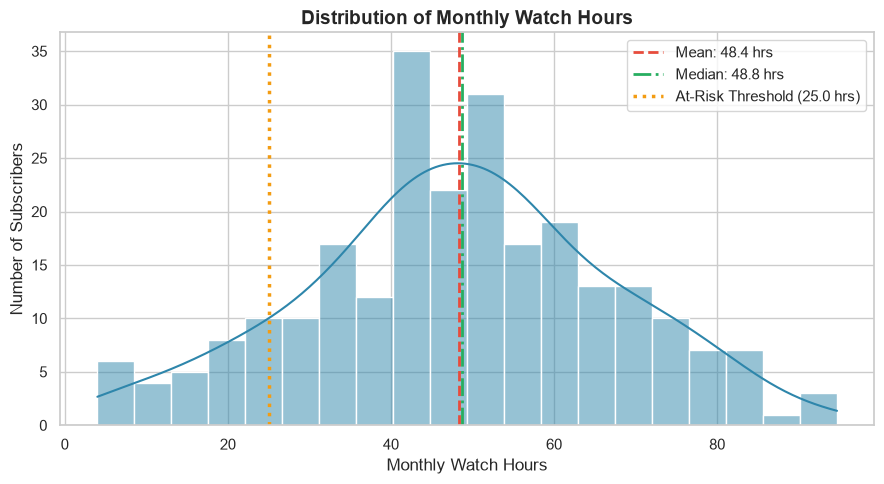

In [6]:
print(df["Monthly_Watch_Hours"].describe().round(2))

fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(df["Monthly_Watch_Hours"], bins=20, kde=True, color="#2E86AB", ax=ax)
ax.axvline(df["Monthly_Watch_Hours"].mean(), color="#E74C3C", linestyle="--", linewidth=2,
           label=f"Mean: {df['Monthly_Watch_Hours'].mean():.1f} hrs")
ax.axvline(df["Monthly_Watch_Hours"].median(), color="#27AE60", linestyle="-.", linewidth=2,
           label=f"Median: {df['Monthly_Watch_Hours'].median():.1f} hrs")
ax.axvline(25.0, color="#F39C12", linestyle=":", linewidth=2.5, label="At-Risk Threshold (25.0 hrs)")
ax.set_title("Distribution of Monthly Watch Hours", fontsize=14, fontweight="bold")
ax.set_xlabel("Monthly Watch Hours")
ax.set_ylabel("Number of Subscribers")
ax.legend()
plt.tight_layout()
plt.savefig("../images/chart1_watch_hours_distribution.png", dpi=150)
plt.show()

Correlations with Monthly_Watch_Hours:
Viewer_Age                -0.011
Monthly_Fee_INR            0.056
Weekly_App_Opens           0.553
Recommendation_Clicks      0.571
Cost_Per_Watch_Hour_INR   -0.520
Monthly_Watch_Hours        1.000
Name: Monthly_Watch_Hours, dtype: float64


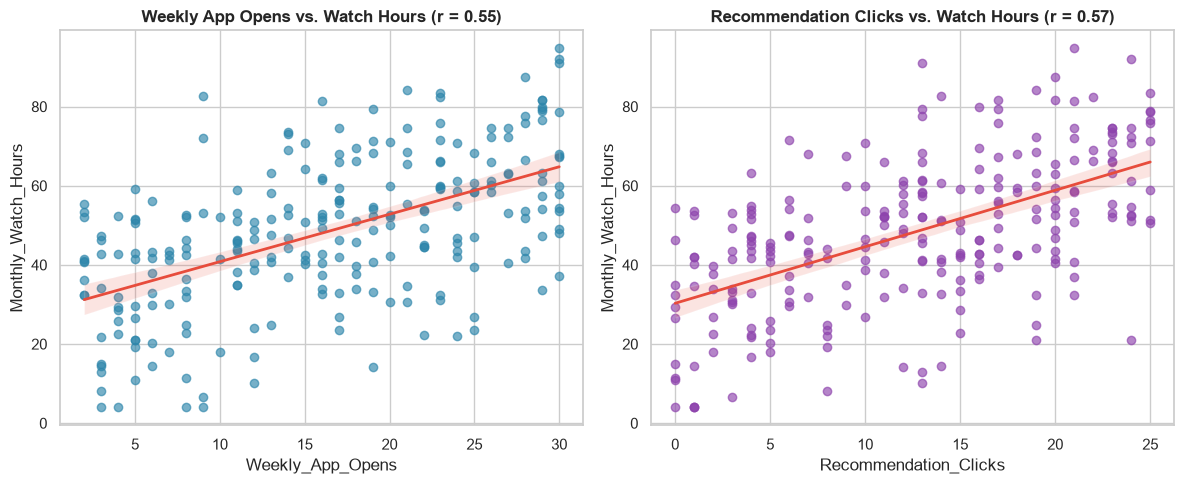

In [7]:
num_cols = ["Viewer_Age", "Monthly_Fee_INR", "Weekly_App_Opens",
            "Recommendation_Clicks", "Cost_Per_Watch_Hour_INR", "Monthly_Watch_Hours"]
print("Correlations with Monthly_Watch_Hours:")
print(df[num_cols].corr()["Monthly_Watch_Hours"].round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

r_opens = df["Weekly_App_Opens"].corr(df["Monthly_Watch_Hours"])
sns.regplot(x="Weekly_App_Opens", y="Monthly_Watch_Hours", data=df,
            scatter_kws={"alpha": 0.65, "color": "#2E86AB"},
            line_kws={"color": "#E74C3C", "linewidth": 2}, ax=axes[0])
axes[0].set_title(f"Weekly App Opens vs. Watch Hours (r = {r_opens:.2f})", fontweight="bold")

r_clicks = df["Recommendation_Clicks"].corr(df["Monthly_Watch_Hours"])
sns.regplot(x="Recommendation_Clicks", y="Monthly_Watch_Hours", data=df,
            scatter_kws={"alpha": 0.65, "color": "#8E44AD"},
            line_kws={"color": "#E74C3C", "linewidth": 2}, ax=axes[1])
axes[1].set_title(f"Recommendation Clicks vs. Watch Hours (r = {r_clicks:.2f})", fontweight="bold")

plt.tight_layout()
plt.savefig("../images/chart2_numeric_relationships.png", dpi=150)
plt.show()


Average Monthly_Watch_Hours by Primary_Device:
                count   mean  median
Primary_Device                      
Laptop             49  48.64   47.40
Smart TV           77  52.39   52.00
Smartphone        124  45.76   46.05

Average Monthly_Watch_Hours by Subscription_Plan:
                   count   mean  median
Subscription_Plan                      
Mobile               112  46.71   48.75
Premium               49  50.64   50.80
Standard              89  49.20   46.90

Average Monthly_Watch_Hours by City:
           count   mean  median
City                           
Bengaluru     49  48.80    48.7
Delhi         63  48.81    46.3
Hyderabad     37  50.14    47.6
Mumbai        71  48.21    52.0
Pune          30  44.91    44.0

Average Monthly_Watch_Hours by Preferred_Genre:
                 count   mean  median
Preferred_Genre                      
Action              35  51.68   54.30
Comedy              45  46.33   47.00
Documentary         27  50.81   51.30
Drama          

C:\Users\samar\AppData\Local\Temp\ipykernel_4520\3094638630.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=col, y="Monthly_Watch_Hours", data=df, order=order,
C:\Users\samar\AppData\Local\Temp\ipykernel_4520\3094638630.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=col, y="Monthly_Watch_Hours", data=df, order=order,
C:\Users\samar\AppData\Local\Temp\ipykernel_4520\3094638630.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=col, y="Monthly_Watch_Hours", data=df, order=order,
C:\Users\samar\AppData\Local\Temp\ipykernel_45

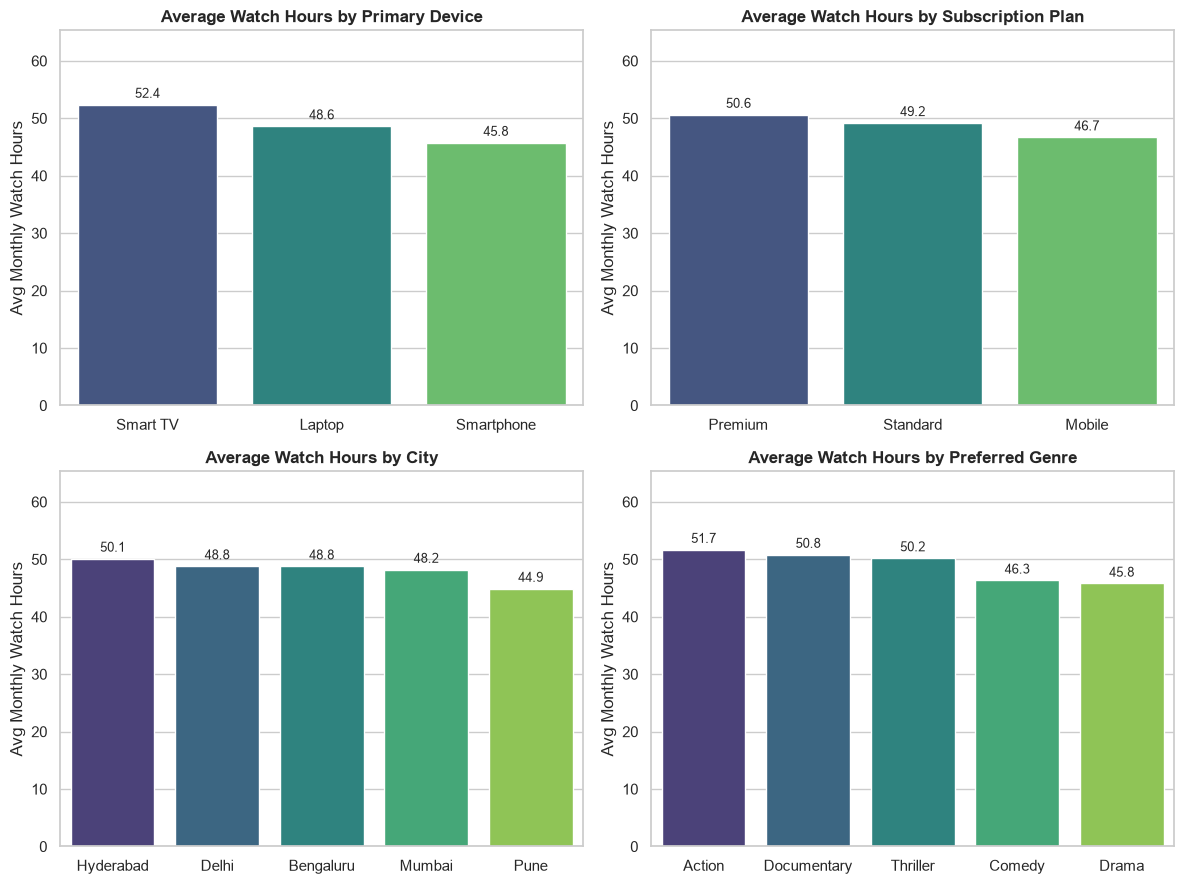

In [8]:
for col in ["Primary_Device", "Subscription_Plan", "City", "Preferred_Genre"]:
    print(f"\nAverage Monthly_Watch_Hours by {col}:")
    print(df.groupby(col)["Monthly_Watch_Hours"].agg(["count", "mean", "median"]).round(2))

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
categories = [
    ("Primary_Device", "Average Watch Hours by Primary Device"),
    ("Subscription_Plan", "Average Watch Hours by Subscription Plan"),
    ("City", "Average Watch Hours by City"),
    ("Preferred_Genre", "Average Watch Hours by Preferred Genre")
]

for ax, (col, title) in zip(axes.flat, categories):
    order = df.groupby(col)["Monthly_Watch_Hours"].mean().sort_values(ascending=False).index
    sns.barplot(x=col, y="Monthly_Watch_Hours", data=df, order=order,
                errorbar=None, palette="viridis", ax=ax)
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Avg Monthly Watch Hours")
    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f", padding=3, fontsize=9)
    ax.set_ylim(0, df["Monthly_Watch_Hours"].mean() * 1.35)

plt.tight_layout()
plt.savefig("../images/chart3_category_comparison.png", dpi=150)
plt.show()

At-Risk Subscribers: 31 (12.4%)
Avg Watch Hours (At Risk): 16.15
Avg Weekly App Opens (At Risk vs Others): 9.06 vs 17.33
Avg Recommendation Clicks (At Risk vs Others): 6.81 vs 13.48
Avg Cost/Hour INR (At Risk vs Others): ₹29.51 vs ₹8.39


C:\Users\samar\AppData\Local\Temp\ipykernel_4520\3868912846.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Engagement_Status", data=df, order=status_order,


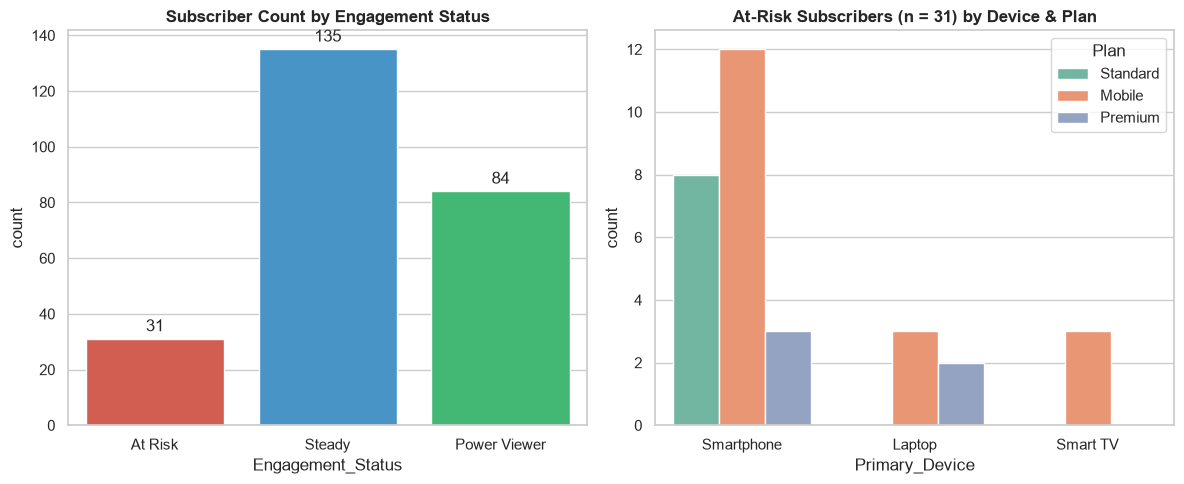

In [9]:
at_risk = df[df["Engagement_Status"] == "At Risk"]
others = df[df["Engagement_Status"] != "At Risk"]

print(f"At-Risk Subscribers: {len(at_risk)} ({len(at_risk)/len(df)*100:.1f}%)")
print(f"Avg Watch Hours (At Risk): {at_risk['Monthly_Watch_Hours'].mean():.2f}")
print(f"Avg Weekly App Opens (At Risk vs Others): {at_risk['Weekly_App_Opens'].mean():.2f} vs {others['Weekly_App_Opens'].mean():.2f}")
print(f"Avg Recommendation Clicks (At Risk vs Others): {at_risk['Recommendation_Clicks'].mean():.2f} vs {others['Recommendation_Clicks'].mean():.2f}")
print(f"Avg Cost/Hour INR (At Risk vs Others): ₹{at_risk['Cost_Per_Watch_Hour_INR'].mean():.2f} vs ₹{others['Cost_Per_Watch_Hour_INR'].mean():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
status_order = ["At Risk", "Steady", "Power Viewer"]
sns.countplot(x="Engagement_Status", data=df, order=status_order,
              palette=["#E74C3C", "#3498DB", "#2ECC71"], ax=axes[0])
axes[0].set_title("Subscriber Count by Engagement Status", fontweight="bold")
for container in axes[0].containers:
    axes[0].bar_label(container, padding=3)

sns.countplot(x="Primary_Device", hue="Subscription_Plan", data=at_risk, palette="Set2", ax=axes[1])
axes[1].set_title(f"At-Risk Subscribers (n = {len(at_risk)}) by Device & Plan", fontweight="bold")
axes[1].legend(title="Plan")

plt.tight_layout()
plt.savefig("../images/chart4_at_risk_viewers.png", dpi=150)
plt.show()

## Key Insights
* **Overall Watch Time:** Subscribers watch an average of **48.37 hours/month** (median **48.75 hours**, range **4.0 to 94.7 hours**).
* **Main Drivers:** `Recommendation_Clicks` (**r = 0.57**) and `Weekly_App_Opens` (**r = 0.55**) strongly drive watch time, whereas `Viewer_Age` (**r = -0.01**) and `Monthly_Fee_INR` (**r = 0.06**) have almost no effect.
* **Device & Plan Gaps:** **Smart TV** users watch the most (**52.39 hrs/month**) compared to **Smartphone** users (**45.76 hrs**). **Premium** subscribers lead (**50.64 hrs**) over **Mobile** (**46.71 hrs**).
* **At-Risk Profile:** **31 subscribers (12.4%)** are At Risk (< 25.0 hrs). They open the app half as often (**9.06 vs. 17.33/week**), click half as many recommendations (**6.81 vs. 13.48/month**), and pay **3.5x more per hour watched** (**₹29.51 vs. ₹8.39**). **74.2% (23/31)** stream on Smartphones and **58.1% (18/31)** are on the Mobile plan.

## Recommendations
1. **Trigger Early Mobile Re-engagement:** Send personalized push notifications and weekend watchlists when a Smartphone/Mobile-plan subscriber drops below 10 weekly app opens.
2. **Upgrade the Recommendation Feed:** Since recommendation clicks are the top driver (r = 0.57), surface short high-hook trailers and "Continue Watching" cards at the top of the home screen.
3. **Promote Big-Screen Trials:** Offer engaged Mobile users a free 14-day Smart TV / Standard-plan trial to capture the +6.6 hour/month engagement lift.
4. **Target Pune & Drama Viewers:** Run curated regional mini-series campaigns aimed at Pune (lowest city average at 44.91 hrs) and Drama viewers (14 of 31 At-Risk users).

In [10]:
df.to_csv("../data/processed/ott_viewing_data_clean.csv", index=False)
print("Saved cleaned dataset to ../data/processed/ott_viewing_data_clean.csv")

Saved cleaned dataset to ../data/processed/ott_viewing_data_clean.csv
